In [1]:
# Import Python packages
import sys
import os
import subprocess
import matplotlib.pyplot as plt
import numpy as np
import scipy.constants as const

# Import the Simulation packages
project_directory = subprocess.check_output(['git', 'rev-parse', '--show-toplevel']).strip().decode('utf-8')
sys.path.append(project_directory + '/spinsimulation')  # Remove the square brackets
from SpinSys import SpinSys
import SpinHamiltonian as hamil 
import calcdIdV as dIdV
import calcESR as ESR
import SpinVisualization as vis
%load_ext autoreload
%autoreload 2

In [4]:
# Define the Spin System
Spins=[1,0.5,1,0.5]
spinsys = SpinSys(Spins)
spinsys.B=[0,0,0.5]
spinsys.BTip=[1e-7,0,0]
spinsys.tip='f'
spinsys.TipPolarization=[0,0,0.4]
spinsys.T=1
spinsys.Jvector[0,:]=np.array([14.65,14.6,14.6])
spinsys.Jvector[5,:]=np.array([14.65,14.6,14.6])
spinsys.Jvector[3,:]=np.array([1.0*spinsys.GHztomeVConversion,1.0*spinsys.GHztomeVConversion,1.0*spinsys.GHztomeVConversion])
spinsys.Dvector=np.array([-1.9,0,-1.9,0])
spinsys.AtomPositions=np.array([[0,0,0],[2,1,0],[5,1,0],[7,2,0]])
spinsys.DipoleBool=[False,False,False,True,False,False]
spinsys.V_DC=-100
#print(S.D)

### Visualize the Eigenstates

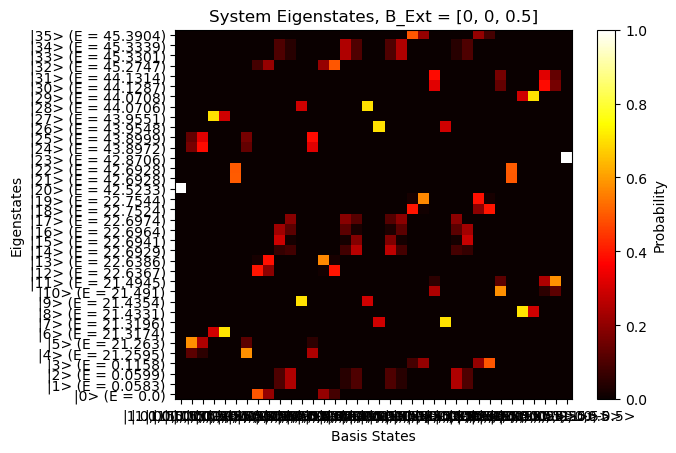

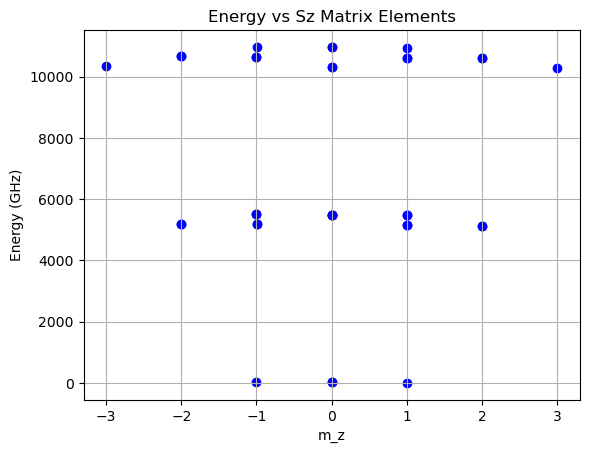

In [6]:
vis.plotEigenMatrix(spinsys)
vis.plotEnergyVsSz(spinsys)

### ESR Experiments

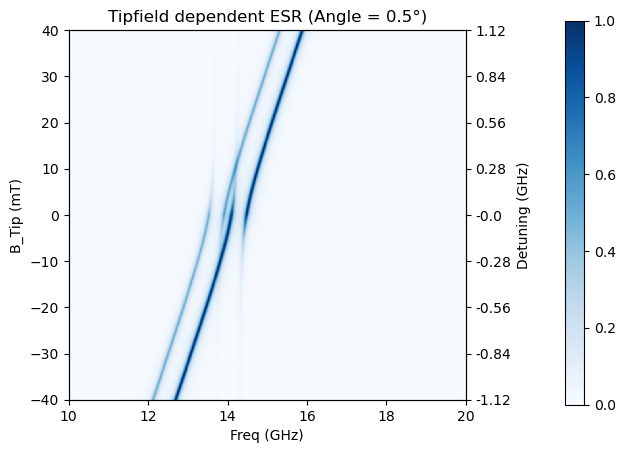

In [34]:
spinsys.ReadoutSpin=0 
spinsys.BTip=[1e-6,0,0.1]
spinsys.T=1
hamil.calcEigEnergies(spinsys)
#vis.plotESR_FreqSweep(spinsys, FreqRange=[12,17],N=500, norm=False, lw=0.1,AllowPumping=False)
vis.plotESR_Tipfieldsweep(spinsys, Angle=0.5,lw=0.1,BTipRange=[-0.04,0.04],N_B=1000,N_Freq=1000,AllowPumping=False,norm=True)
